In [1]:
import rasterio
import xarray as xr
import glob
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import re

from rasterio.transform import rowcol
from pyproj import Proj, transform, Transformer
from rasterio.merge import merge
from rasterio.transform import from_bounds
from datetime import datetime, timedelta
from scipy.optimize import curve_fit
from scipy.ndimage import uniform_filter1d

# Path to your merged raster file
raster_path = "H:/My Drive/NDVI_Exports//Merged/WY_NDVI_2018.tif"

# Read the merged raster file
with rasterio.open(raster_path) as src:
    # Read all bands into a numpy array
    stacked_data = src.read()  # shape: (bands, height, width)
    raster_crs = src.crs  # Get the raster CRS
    native_transform = src.transform  # Affine transformation matrix

print("Original Stacked Data Shape:", stacked_data.shape)

Original Stacked Data Shape: (46, 812, 1034)


In [2]:
# Temporal smoothing function using a moving average
def smooth_temporal(data, window_size=3):
    """
    Smooths the temporal dimension of the stacked raster data using a moving average.

    Parameters:
    - data: numpy array of shape (bands, height, width)
    - window_size: size of the moving window (must be an odd integer)

    Returns:
    - smoothed_data: numpy array of shape (bands, height, width)
    """
    smoothed_data = uniform_filter1d(data, size=window_size, axis=0, mode='nearest')
    return smoothed_data


In [3]:
# Step 1: Temporal smoothing
window_size = 5  # Define the moving window size (adjust as needed)
smoothed_data = smooth_temporal(stacked_data, window_size=window_size)

# Verify smoothing
print("Smoothed Data Shape:", smoothed_data.shape)

# Step 2: Replace all-NaN pixels
valid_mask = ~np.isnan(smoothed_data).all(axis=0)  # Mask for valid pixels
min_val = np.full(smoothed_data.shape[1:], np.nan)  # Default to NaN
upper_quantile = np.full(smoothed_data.shape[1:], np.nan)

# Only compute for valid pixels
min_val[valid_mask] = np.nanmin(smoothed_data[:, valid_mask], axis=0)
upper_quantile[valid_mask] = np.nanquantile(smoothed_data[:, valid_mask], 0.975, axis=0)

# Fill remaining NaNs with defaults
min_val = np.nan_to_num(min_val, nan=0.0)
upper_quantile = np.nan_to_num(upper_quantile, nan=1.0)

# Expand arrays for broadcasting
upper_quantile_expanded = upper_quantile[np.newaxis, :, :]
min_val_expanded = min_val[np.newaxis, :, :]

# Step 3: Scale NDVI values
epsilon = 1e-10
denominator = upper_quantile_expanded - min_val_expanded + epsilon
scaled_data = (smoothed_data - min_val_expanded) / denominator
scaled_data = np.clip(scaled_data, 0, 1)  # Ensure scaled values stay within [0, 1]

# Verify the range of scaled data
print("Scaled Data Min:", np.nanmin(scaled_data))
print("Scaled Data Max:", np.nanmax(scaled_data))
print("Upper Quantile (97.5th percentile):", np.nanmax(upper_quantile))
print("Minimum NDVI (per pixel):", np.nanmin(min_val))


Smoothed Data Shape: (46, 812, 1034)
Scaled Data Min: 0.0
Scaled Data Max: 1.0
Upper Quantile (97.5th percentile): 1.0
Minimum NDVI (per pixel): 0.0


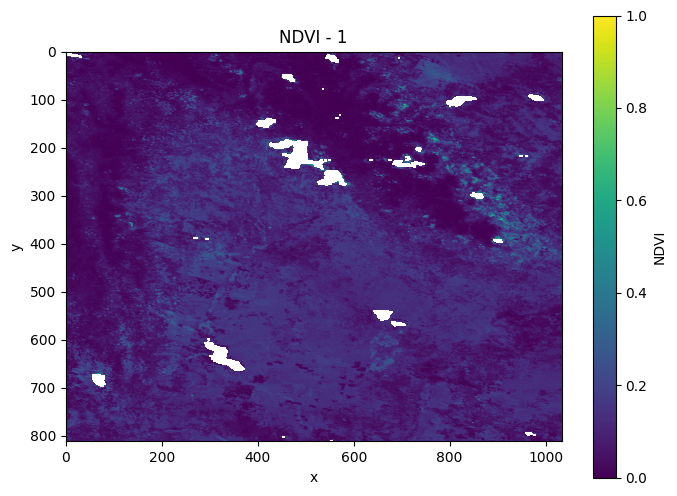

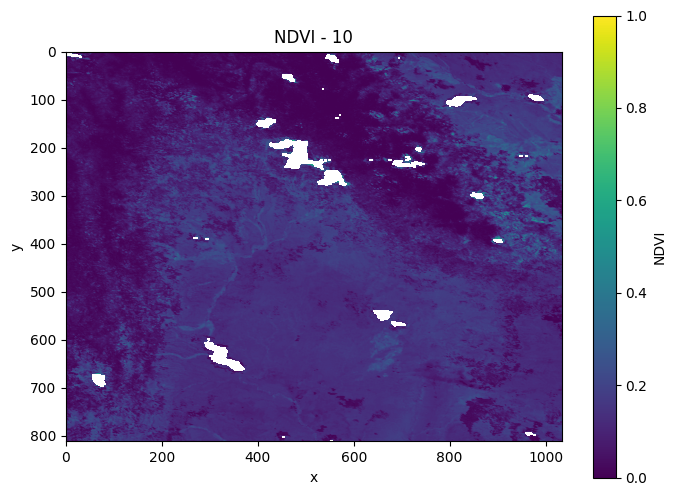

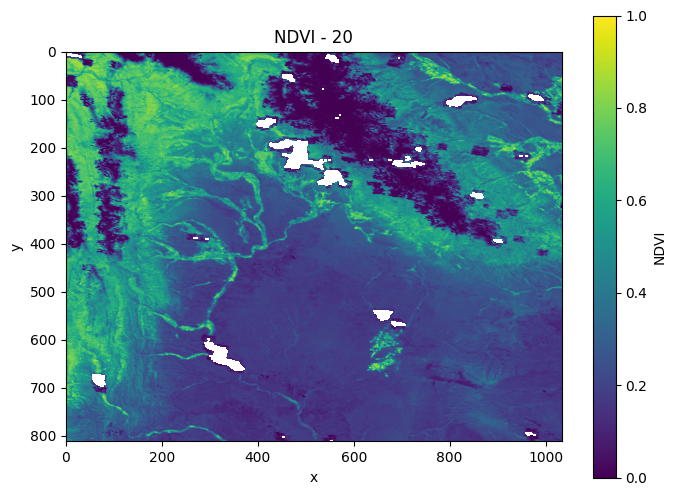

In [4]:
# Plot the first 8-day NDVI layer
plt.figure(figsize=(8, 6))
plt.imshow(stacked_data[0, :, :], cmap="viridis", origin="upper", vmin=0, vmax=1)
plt.colorbar(label="NDVI")
plt.title("NDVI - 1")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

plt.figure(figsize=(8, 6))
plt.imshow(stacked_data[10, :, :], cmap="viridis", origin="upper", vmin=0, vmax=1)
plt.colorbar(label="NDVI")
plt.title("NDVI - 10")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

plt.figure(figsize=(8, 6))
plt.imshow(stacked_data[20, :, :], cmap="viridis", origin="upper", vmin=0, vmax=1)
plt.colorbar(label="NDVI")
plt.title("NDVI - 20")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [5]:
# DLC model for NDVI calculation
def dlc_model(time, xmidS, scalS, xmidA, scalA):
    return (1 / (1 + np.exp((xmidS - time) / scalS))) - (1 / (1 + np.exp((xmidA - time) / scalA)))

# Spring green-up curve (first logistic function)
def spring_curve(time, xmidS, scalS):
    return 1 / (1 + np.exp((xmidS - time) / scalS))

# IRG calculation
def calculate_irg(ndvi_values, time, scale_irg=True):
    """
    Calculate the Instantaneous Rate of Green-up (IRG) from NDVI values.

    Parameters:
        ndvi_values (numpy.ndarray): 3D array (time x rows x cols) of NDVI values.
        time (numpy.ndarray): 1D array of time steps corresponding to NDVI values.
        scale_irg (bool): Scale IRG values between 0 and 1.

    Returns:
        numpy.ndarray: 3D array (time x rows x cols) of IRG values.
    """
    # Calculate IRG as the temporal difference normalized by time differences
    time_diff = np.diff(time).reshape(-1, 1, 1)  # Reshape to (time-1, 1, 1) for broadcasting
    irg = np.diff(ndvi_values, axis=0) / time_diff

    # Set negative IRG values to 0
    irg = np.maximum(irg, 0)

    # Scale IRG if requested
    if scale_irg and np.any(~np.isnan(irg)):
        irg_min, irg_max = np.nanmin(irg), np.nanmax(irg)
        irg = (irg - irg_min) / (irg_max - irg_min) if irg_max > irg_min else irg

    # Pad with NaN to maintain the same temporal shape
    irg = np.pad(irg, ((1, 0), (0, 0), (0, 0)), constant_values=np.nan)

    return irg


# Find the date corresponding to a max or min value
def find_peak_or_valley(values, dates, peak=True):
    """
    Find the date corresponding to the peak (max) or valley (min) for each pixel.

    Parameters:
        values (numpy.ndarray): 3D array (time x rows x cols) of values.
        dates (numpy.ndarray): 1D array of dates corresponding to the time axis.
        peak (bool): If True, find the peak (max); if False, find the valley (min).

    Returns:
        numpy.ndarray: 2D array (rows x cols) of dates corresponding to peaks or valleys.
    """
    result = np.full(values.shape[1:], np.nan)  # Initialize result with NaNs (rows x cols)

    for row in range(values.shape[1]):  # Iterate over rows
        for col in range(values.shape[2]):  # Iterate over columns
            pixel_values = values[:, row, col]  # Time series for the pixel

            if np.isnan(pixel_values).all():  # Skip all-NaN slices
                continue

            if peak:
                max_index = np.nanargmax(pixel_values)  # Index of max value
            else:
                max_index = np.nanargmin(pixel_values)  # Index of min value

            result[row, col] = dates[max_index]  # Assign the corresponding date

    return result


In [6]:
# years = list(range(2018, 2024))  # Use 2024 as the end point to include 2023
years = [2018, 2019, 2020, 2021]
years = [2018]

## get the dates
dates = []
for year in years:
    start_date = datetime(year, 1, 1)
    dates.extend([start_date + timedelta(days=8 * i) for i in range(46)])  # 46 intervals in 365-day year

dates = pd.to_datetime(dates)

## intial parameters to try for the DLC
dlc_bounds = ([30, 1, 167, 1], [228, 30, 288, 35])

## run the function for each pixel seperately
def fit_dlc_per_pixel(ndvi_data, time, dlc_bounds):
    if np.isnan(ndvi_data).any() or len(ndvi_data[~np.isnan(ndvi_data)]) < 4:
        return [np.nan] * 8  # return NaNs if insufficient data

    try:
        ## initial parameter guesses
        initial_guess = [130, 10, 230, 17]
        
        ## perform the curve fitting
        popt, pcov = curve_fit(dlc_model, time, ndvi_data, p0=initial_guess, bounds=dlc_bounds)
        
        ## extract standard errors from the covariance matrix
        perr = np.sqrt(np.diag(pcov))
        
        ## return parameters and standard errors
        return list(popt) + list(perr)
    
    except Exception as e:
        print(f"Error fitting pixel: {e}")
        return [np.nan] * 8

## process the data for each year seperately
def fit_dlc_for_year(ndvi_stack, dates, years, dlc_bounds):
    results = []
    
    for year in years:
        # Subset NDVI data to current year
        year_indices = [i for i, date in enumerate(dates) if date.year == year]
        ndvi_year = ndvi_stack[year_indices]
        time = np.array([date.timetuple().tm_yday for i, date in enumerate(dates) if date.year == year])
        
        # Initialize result array for current year
        dlc_params = np.full((*ndvi_year.shape[1:], 8), np.nan)
        
        # Loop over each pixel
        for row in range(ndvi_year.shape[1]):
            for col in range(ndvi_year.shape[2]):
                ndvi_pixel = ndvi_year[:, row, col]
                dlc_params[row, col, :] = fit_dlc_per_pixel(ndvi_pixel, time, dlc_bounds)
                
        results.append(dlc_params)
    
    return np.stack(results, axis=0)  # Shape: (years, rows, cols, params)


## fit the DLC model for each year
dlc_results = fit_dlc_for_year(scaled_data, dates, years, dlc_bounds)

print("DLC Parameters Shape:", dlc_results.shape) ## years, rows, columns, parameters

DLC Parameters Shape: (1, 812, 1034, 8)


In [7]:
latitude =  42.7398  # Replace with your latitude
longitude = -108.9312  # Replace with your longitude

transformer = Transformer.from_crs("EPSG:4326", raster_crs, always_xy=True)
x, y = transformer.transform(longitude, latitude)

print(x, y)
print("Smoothed Data Shape:", smoothed_data.shape)
print("Raw Data Shape:", stacked_data.shape)

-108.9312 42.7398
Smoothed Data Shape: (46, 812, 1034)
Raw Data Shape: (46, 812, 1034)


Latitude: 42.24772, Longitude: -110.1388 -> Row: 559, Col: 319


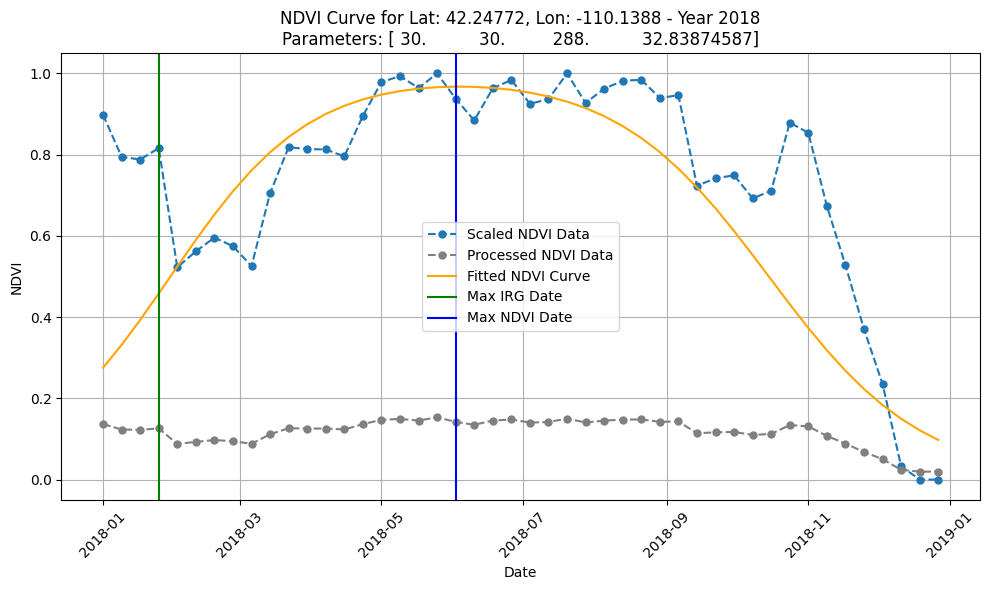

Latitude: 42.71927, Longitude: -108.911 -> Row: 332, Col: 909


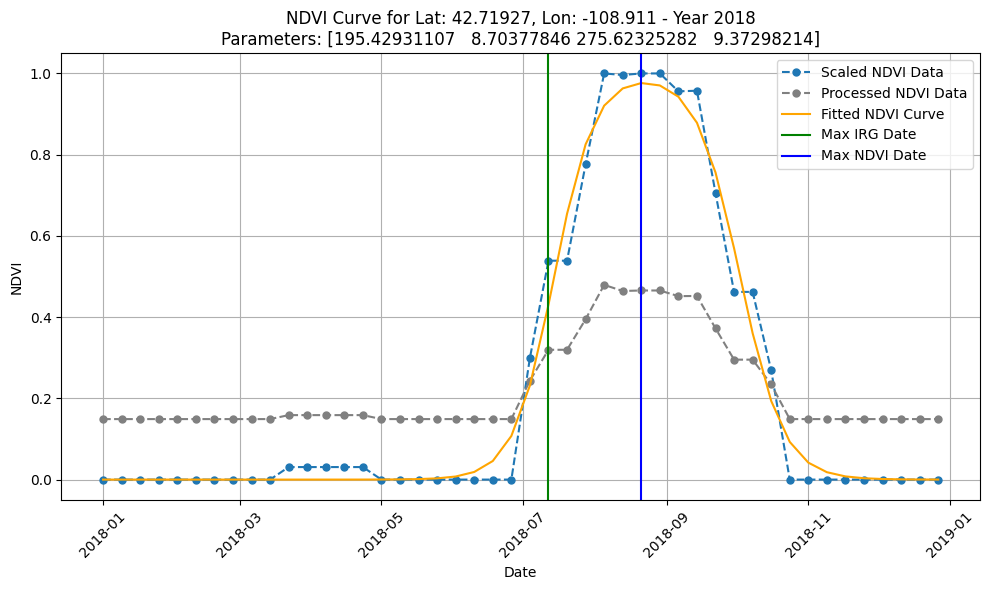

Latitude: 43.187476, Longitude: -109.7319 -> Row: 107, Col: 514


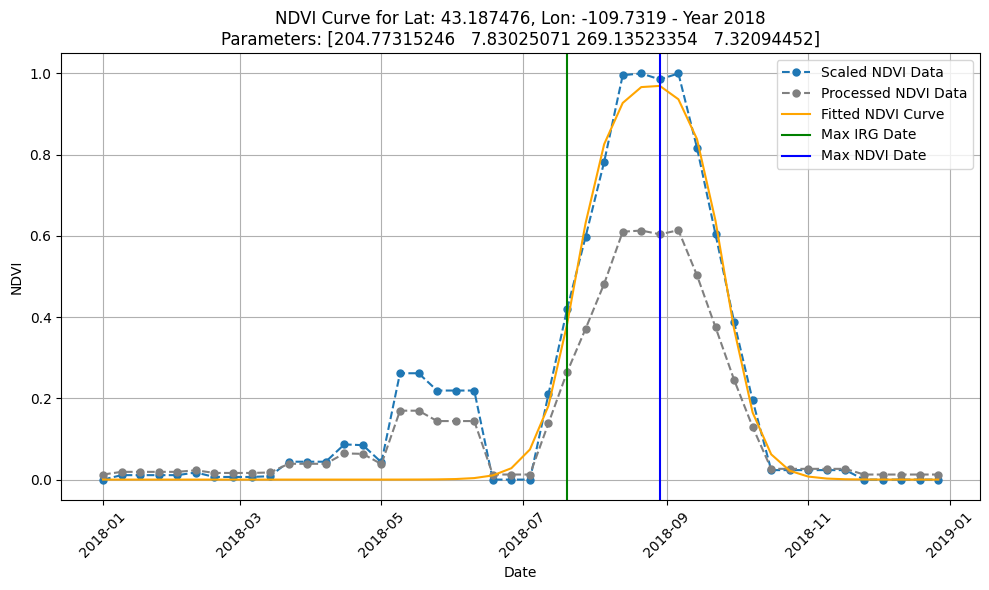

In [15]:
# Function to calculate fitted NDVI values for specific dates
def calculate_fitted_ndvi(dlc_params, time_points):
    return dlc_model(time_points, *dlc_params)

# Updated function to plot NDVI and curves for a specific latitude and longitude
def plot_ndvi_latlon(dlc_results, stacked_data, scaled_data, dates, lat, lon, transform, years):
    
    # Convert latitude and longitude to row and column indices
    transformer = Transformer.from_crs("EPSG:4326", raster_crs, always_xy=True)
    x, y = transformer.transform(longitude, latitude)

    row, col = rowcol(transform, x, y)
    print(f"Latitude: {lat}, Longitude: {lon} -> Row: {row}, Col: {col}")
    
    # Plotting setup
    fig, ax = plt.subplots(len(years), 1, figsize=(10, 6 * len(years)))
    if len(years) == 1:
        ax = [ax]  # Ensure ax is always a list for easy indexing
    
    for i, year in enumerate(years):
        # Extract parameters for the current year and pixel
        params = dlc_results[i, row, col, :4]  # First 4 values are the fitted parameters
        
        # Get the dates and time points for 8-day intervals
        year_dates = np.array([date for date in dates if date.year == year])
        time_points = np.array([date.timetuple().tm_yday for date in year_dates])
        
        # Generate fitted curve if parameters are valid
        if not np.isnan(params).any():
            fitted_curve = calculate_fitted_ndvi(params, time_points)
            
            # Calculate IRG and find max dates (for 8-day intervals)
            irg_vals = np.diff(fitted_curve)
            max_irg_idx = np.nanargmax(irg_vals)
            max_ndvi_idx = np.nanargmax(fitted_curve)
            
            max_irg_date = year_dates[max_irg_idx]
            max_ndvi_date = year_dates[max_ndvi_idx]
        else:
            fitted_curve = None
            max_irg_date = max_ndvi_date = None
            print(f"No valid parameters for pixel ({row}, {col}) in {year}")
        
        # Extract raw NDVI values for the current year and pixel
        year_indices = [j for j, date in enumerate(dates) if date.year == year]
        ndvi_values = scaled_data[year_indices, row, col]
        ndvi_values_raw = stacked_data[year_indices, row, col]
        
        # Plot raw NDVI data
        ax[i].plot(year_dates, ndvi_values, 'o', label="Scaled NDVI Data", linestyle='--', markersize=5)
        ax[i].plot(year_dates, ndvi_values_raw, 'o', label="Processed NDVI Data", linestyle='--', markersize=5, color = "grey")
        
        # Plot fitted DLC curve if available
        if fitted_curve is not None:
            ax[i].plot(year_dates, fitted_curve, label="Fitted NDVI Curve", color='orange')
            ax[i].set_title(f"NDVI Curve for Lat: {lat}, Lon: {lon} - Year {year}\nParameters: {params}")
            
            # Plot vertical lines at max IRG and max NDVI dates
            if max_irg_date is not None:
                ax[i].axvline(max_irg_date, color='green', linestyle='-', label="Max IRG Date")
            if max_ndvi_date is not None:
                ax[i].axvline(max_ndvi_date, color='blue', linestyle='-', label="Max NDVI Date")
        else:
            ax[i].set_title(f"NDVI Curve for Lat: {lat}, Lon: {lon} - Year {year} (No Fit)")
        
        # Formatting
        ax[i].set_xlabel("Date")
        ax[i].set_ylabel("NDVI")
        ax[i].legend()
        ax[i].grid(True)
        ax[i].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()


## Some weird places in WY that were different than jerod's code
# -110.0903 42.23412
# -109.2682 42.47383

## POINT (-110.1388 42.24772)
latitude =  42.24772  # Replace with your latitude
longitude = -110.1388  # Replace with your longitude
transform = native_transform  # Use the transform from your mosaic

years = [2018]
dates = []
for year in years:
    start_date = datetime(year, 1, 1)
    dates.extend([start_date + timedelta(days=8 * i) for i in range(46)])  # 46 intervals in 365-day year

dates = pd.to_datetime(dates)

# Plot NDVI for the given latitude and longitude
plot_ndvi_latlon(dlc_results, smoothed_data, scaled_data, dates, latitude, longitude, transform, years)

##  (-108.911 42.71927)
latitude =  42.71927  # Replace with your latitude
longitude = -108.911  # Replace with your longitude
transform = native_transform  # Use the transform from your mosaic

# Plot NDVI for the given latitude and longitude
plot_ndvi_latlon(dlc_results, smoothed_data, scaled_data, dates, latitude, longitude, transform, years)


## 43.187476°N 109.731900°W
latitude = 43.187476  # Replace with your latitude
longitude = -109.731900  # Replace with your longitude

# Plot NDVI for the given latitude and longitude
plot_ndvi_latlon(dlc_results, smoothed_data, scaled_data, dates, latitude, longitude, transform, years)


In [9]:
def ndvi_calc_vals(dlc_params, dates, years, values="daily", scl_irg=True):
    """
    Calculate fitted NDVI, IRG, and derived metrics for specified years, including spring scale SE.

    Parameters:
        dlc_params (numpy.ndarray): 4D array (years, rows, cols, 8) with DLC parameters.
        dates (list): List of datetime objects.
        years (list): List of years for calculations.
        values (str): "daily" or "weekly".
        scl_irg (bool): Scale IRG between 0 and 1.

    Returns:
        dict: Contains fitted NDVI, IRG, spring scale SE, and derived metrics as numpy arrays.
    """
    # Time steps
    time = np.arange(1, 366) if values == "daily" else np.arange(1, 366, 7)
    julian_dates = time
    results = {}

    for year_index, year in enumerate(years):
        # DLC parameters for the current year
        params = dlc_params[year_index, :, :, :]  # Shape: (rows, cols, 8)
        xmidS, scalS, xmidA, scalA = params[..., 0], params[..., 1], params[..., 2], params[..., 3]
        scalS_se = params[..., 5]  # Extract scalS SE

        # Fitted NDVI
        ndvi_values = np.array([
            dlc_model(t, xmidS, scalS, xmidA, scalA) for t in time
        ])  # Shape: (time, rows, cols)

        # Spring green-up
        spring_data = np.array([spring_curve(t, xmidS, scalS) for t in time])

        # IRG calculation
        irg = calculate_irg(ndvi_values, time, scale_irg=scl_irg)

        # Calculate metrics
        max_ndvi = np.nanmax(ndvi_values, axis=0)
        max_ndvi_date = find_peak_or_valley(ndvi_values, julian_dates, peak=True)
        max_irg = np.nanmax(irg, axis=0)
        max_irg_date = find_peak_or_valley(irg, julian_dates, peak=True)

        # Second derivative for spring start and end
        second_deriv = np.gradient(np.gradient(spring_data, axis=0), axis=0)
        spring_start = find_peak_or_valley(second_deriv, julian_dates, peak=True)
        spring_end = find_peak_or_valley(second_deriv, julian_dates, peak=False)

        # Store results, including scalS SE
        results[year] = {
            "fitted_ndvi": ndvi_values,
            "spring_curve": spring_data,
            "irg": irg,
            "max_ndvi": max_ndvi,
            "max_ndvi_date": max_ndvi_date,
            "max_irg": max_irg,
            "max_irg_date": max_irg_date,
            "spring_start": spring_start,
            "spring_end": spring_end,
            "scalS_se": scalS_se,  # Include spring scale SE
        }

    return results


In [10]:
# Example usage of the updated function
years = [2018]
dates = [datetime(2018, 1, 1) + timedelta(days=i) for i in range(365)]

# Example usage
results = ndvi_calc_vals(dlc_params=dlc_results, dates=dates, years=years, values="daily", scl_irg=True)

# Access results for 2018
results_2018 = results[2018]
max_ndvi_date_2018 = results_2018["max_ndvi_date"]
max_irg_date_2018 = results_2018["max_irg_date"]
print("Max NDVI Date for 2018:", max_ndvi_date_2018)


C:\Users\tlasharr\AppData\Local\Temp\ipykernel_34400\2444638498.py:38: RuntimeWarning: All-NaN slice encountered
  max_ndvi = np.nanmax(ndvi_values, axis=0)
C:\Users\tlasharr\AppData\Local\Temp\ipykernel_34400\2444638498.py:40: RuntimeWarning: All-NaN slice encountered
  max_irg = np.nanmax(irg, axis=0)


Max NDVI Date for 2018: [[193. 193. 193. ... 182. 182. 168.]
 [ nan  nan 177. ... 182. 204. 185.]
 [ nan 178. 178. ... 180. 195. 199.]
 ...
 [147. 146. 146. ... 185. 178. 178.]
 [150. 146. 144. ... 184. 184. 179.]
 [163. 156. 156. ... 169. 185. 173.]]


In [11]:
import rasterio
import numpy as np

def export_raster_with_multiple_bands(max_irg, max_irg_date, irg_se, max_ndvi, max_ndvi_date, raster_crs, native_transform, output_file):
    """
    Export a raster with multiple bands:
        1. Max IRG values
        2. Max IRG dates
        3. IRG SE
        4. Max NDVI values
        5. Max NDVI dates

    Parameters:
    - max_irg: 2D NumPy array of max IRG values (rows x cols)
    - max_irg_date: 2D NumPy array of max IRG dates (rows x cols)
    - irg_se: 2D NumPy array of IRG standard errors (rows x cols)
    - max_ndvi: 2D NumPy array of max NDVI values (rows x cols)
    - max_ndvi_date: 2D NumPy array of max NDVI dates (rows x cols)
    - raster_crs: CRS of the raster.
    - native_transform: Affine transform of the raster.
    - output_file: Path to the output GeoTIFF file.
    """
    # Check that all arrays have the same dimensions
    height, width = max_irg.shape
    arrays = [max_irg, max_irg_date, irg_se, max_ndvi, max_ndvi_date]
    for array in arrays:
        if array.shape != (height, width):
            raise ValueError(f"Array dimensions do not match. Expected {max_irg.shape}, got {array.shape}.")

    # Metadata for the output raster
    meta = {
        "driver": "GTiff",
        "height": height,
        "width": width,
        "count": 5,  # Number of bands
        "dtype": "float32",
        "crs": raster_crs,
        "transform": native_transform,
    }

    # Combine data into a 3D array for export
    combined_data = np.stack([max_irg, max_irg_date, irg_se, max_ndvi, max_ndvi_date], axis=0)  # Shape: (5, rows, cols)

    # Band names
    band_names = ["max_irg", "max_irg_date", "scalS_se", "max_ndvi", "max_ndvi_date"]

    # Write the data to a GeoTIFF
    with rasterio.open(output_file, "w", **meta) as dst:
        for i in range(5):
            dst.write(combined_data[i, :, :], i + 1)  # Bands are 1-indexed in rasterio
            dst.set_band_description(i + 1, band_names[i])  # Add band name

    print(f"Raster exported successfully to {output_file}")


## get the metrics we want to export
max_irg = results[year]["max_irg"]
max_irg_date = results[year]["max_irg_date"]
irg_se = results[year]["scalS_se"]  # Assuming IRG SE is the same as scalS SE
max_ndvi = results[year]["max_ndvi"]
max_ndvi_date = results[year]["max_ndvi_date"]

print("Shapes:")
print(f"  Max IRG: {max_irg.shape}")
print(f"  Max IRG Date: {max_irg_date.shape}")
print(f"  IRG SE: {irg_se.shape}")
print(f"  Max NDVI: {max_ndvi.shape}")
print(f"  Max NDVI Date: {max_ndvi_date.shape}")

export_raster_with_multiple_bands(
    max_irg, max_irg_date, irg_se, max_ndvi, max_ndvi_date,
    raster_crs, native_transform,
    "H:/My Drive/IRG_Exports/IRG_2018.tif"
)


Shapes:
  Max IRG: (812, 1034)
  Max IRG Date: (812, 1034)
  IRG SE: (812, 1034)
  Max NDVI: (812, 1034)
  Max NDVI Date: (812, 1034)
Raster exported successfully to H:/My Drive/IRG_Exports/IRG_2018.tif
